### Connect to google drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

### import liberaries

In [ ]:
import os
import torch
import torchvision
import numpy as np
import torch.nn as nn
from PIL import Image
import multiprocessing
import torch.optim as optim
import tensorflow as tf
import torchvision.transforms as transforms
from torch.utils.tensorboard import SummaryWriter
from torch.utils.data import Dataset, DataLoader
import zipfile
import os
import matplotlib.pyplot as plt
import torchvision.utils as vutils
from torchvision import transforms
from torchvision.transforms import InterpolationMode, AutoAugmentPolicy, AutoAugment
import math

### Helpers

In [ ]:
def save_checkpoint(gen, disc, path="/content/drive/MyDrive/AnimGen/checkpoint/anim-gan.pth.tar"):
    print("Saving checkpoint ...")
    checkpoint = {
        'gen_state_dict': gen.state_dict(),
        'disc_state_dict': disc.state_dict(),
    }
    torch.save(checkpoint, path)
    print("Checkpoint Saved Successfully !")

def load_checkpoint(gen, disc, path="/content/drive/MyDrive/AnimGen/checkpoint/anim-gan.pth.tar"):
    print("Loading checkpoint ...")
    try:
        checkpoint = torch.load(path)
        gen.load_state_dict(checkpoint['gen_state_dict'])
        disc.load_state_dict(checkpoint['disc_state_dict'])
        print("Checkpoint Loaded Successfully !")
    except Exception as e:
        print(f"Error during checkpoint loading: {e}")

    return gen, disc

def imshow(img, ax=None):
    if ax is None:
        _, ax = plt.subplots()
    if img.is_cuda:
        img = img.cpu()
    img = img.numpy().transpose(1, 2, 0)
    mean = np.array([0.5, 0.5, 0.5])
    std = np.array([0.5, 0.5, 0.5])
    img = (img * std) + mean
    img = np.clip(img, 0, 1)
    ax.imshow(img)
    ax.axis('off')
    if ax is None:
        plt.show()

def show_batch_images(dataloader):
    images = next(iter(dataloader))
    batch_size = len(images)

    n_rows = int(math.sqrt(batch_size))
    n_cols = math.ceil(batch_size / n_rows)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3))
    axes = axes.flatten() if isinstance(axes, np.ndarray) else [axes]

    mean = np.array([0.5, 0.5, 0.5])
    std = np.array([0.5, 0.5, 0.5])

    for img, ax in zip(images, axes):
        img = img.numpy().transpose(1, 2, 0)
        img = (img * std) + mean
        img = np.clip(img, 0, 1)
        ax.imshow(img)
        ax.axis('off')

    for i in range(len(images), len(axes)):
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

def show_single_image(dataloader):
    plt.figure(figsize=(8, 8))
    image = next(iter(dataloader))[0]
    mean = np.array([0.5, 0.5, 0.5])
    std = np.array([0.5, 0.5, 0.5])
    image = image.numpy().transpose(1, 2, 0)
    image = (image * std) + mean
    image = np.clip(image, 0, 1)
    plt.imshow(image)
    plt.axis('off')
    plt.show()

In [ ]:
# Residual Block (helps to fight exploding and vanashing gradients)
class ResBlock(nn.Module):
    def __init__(self, c_dim):
        super(ResBlock, self).__init__()
        self.net = nn.Sequential(
            nn.Conv2d(c_dim, c_dim, kernel_size=3, stride=1, padding=1, bias=False),
            nn.InstanceNorm2d(c_dim, affine=True, track_running_stats=True),
            nn.ReLU(inplace=True),
            nn.Conv2d(c_dim, c_dim, kernel_size=3, stride=1, padding=1, bias=False),
            nn.InstanceNorm2d(c_dim, affine=True, track_running_stats=True))

    def forward(self, x):
        out = x + self.net(x)
        return out


################################
images = torch.randn(1, 4, 128, 128)
print(images.shape)
resnet = ResBlock(c_dim=4)

output = resnet(images)
output.shape

In [ ]:
def up_cnv_block(in_dim, out_dim, kernel_size, stride, padding, bias=False, is_norm=True):
    layers = [nn.ConvTranspose2d(in_dim, out_dim, kernel_size=kernel_size, stride=stride, padding=padding, bias=bias)]
    if is_norm:
        layers.append(nn.InstanceNorm2d(out_dim, affine=True, track_running_stats=True))
    layers.append(nn.ReLU(inplace=True))
    return nn.Sequential(*layers)

def down_cnv_block(in_dim, out_dim, kernel_size, stride, padding, bias=False, is_norm=True):
    layers = [nn.Conv2d(in_dim, out_dim, kernel_size=kernel_size, stride=stride, padding=padding, bias=bias)]
    if is_norm:
        layers.append(nn.InstanceNorm2d(out_dim, affine=True, track_running_stats=True))
    layers.append(nn.ReLU(inplace=True))
    return nn.Sequential(*layers)

In [ ]:
def set_seed(seed_value=42):
    """Set seed for reproducibility."""
    torch.manual_seed(seed_value)
    torch.cuda.manual_seed(seed_value)
    torch.cuda.manual_seed_all(seed_value)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def get_noise(n_batch, z_dim, device='cpu'):
    """Generate random noise vector with fixed seed for reproducibility."""
    set_seed()
    return torch.randn(n_batch, z_dim, device=device)

### Building Discriminator

In [ ]:
class Discriminator(nn.Module):
    """
    A Discriminator network for image classification with optional residual blocks.

    Attributes:
        im_size (int): Input image size (assumed square).
        c_dim (int): Number of channels in the input image.
        init_dim (int): Dimensionality of the initial convolution layer output.
        n_resnets (int): Number of residual blocks to include.
    """
    def __init__(self, im_size=128, c_dim=3, init_dim=64, n_resnets=1):
        super(Discriminator, self).__init__()
        kernel_size, stride, padding = 4, 2, 1
        layers = []

        # Bottleneck layers.
        for i in range(n_resnets):
            layers.append(ResBlock(c_dim=c_dim))

        layers.append(nn.Conv2d(3, init_dim, kernel_size=4, stride=2, padding=1))
        layers.append(nn.LeakyReLU(0.01))

        curr_dim = init_dim
        out_size = im_size
        while out_size > 4:
            out_size = (out_size + 2 * padding - kernel_size) // stride + 1
            layers.append(down_cnv_block(curr_dim, curr_dim*2, kernel_size=kernel_size, stride=stride, padding=padding, bias=False, is_norm=out_size > 1))
            curr_dim *= 2

        layers.append(nn.Conv2d(curr_dim, 1, kernel_size=3, stride=2, padding=1, bias=False))

        layers.append(nn.Sigmoid())
        self.convnets = nn.Sequential(*layers)

    def forward(self, x):
        out = self.convnets(x)
        return out


##################################
b, c, h, w = 2, 3, 512, 512
images = torch.randn(b, c, h, w)

discriminator = Discriminator(im_size=h, c_dim=c, init_dim=64, n_resnets=1)
output = discriminator(images)
print(output.shape)
print(output)

### Build Generator

In [ ]:
class Generator(nn.Module):
    def __init__(self, im_size=128, c_dim=3, z_dim=64, init_size=16, n_resnets=1, n_cnv=1):
        super(Generator, self).__init__()
        self.z_dim = z_dim
        self.c_dim = c_dim
        self.init_size = init_size
        self.im_size = im_size

        # Project noise to initial tensor
        self.proj = nn.Sequential(
            nn.Linear(z_dim, c_dim * init_size * init_size),
            nn.ReLU(True)
        )

        layers = [down_cnv_block(c_dim, c_dim, kernel_size=7, stride=1, padding=3, bias=False)]

        # build target image dim
        curr_size = init_size
        while curr_size < im_size:
            next_size = curr_size * 2
            layers.append(up_cnv_block(c_dim, c_dim, kernel_size=4, stride=2, padding=1, bias=False))
            curr_size = next_size

        # Down-sampling layers.
        curr_dim = c_dim
        for i in range(n_cnv):
            layers.append(down_cnv_block(curr_dim, curr_dim*2, kernel_size=4, stride=2, padding=1, bias=False))
            curr_dim = curr_dim * 2

        # Bottleneck layers.
        for i in range(n_resnets):
            layers.append(ResBlock(c_dim=curr_dim))

        # Up-sampling layers.
        for i in range(n_cnv):
            layers.append(up_cnv_block(curr_dim, curr_dim//2, kernel_size=4, stride=2, padding=1, bias=False))
            curr_dim = curr_dim // 2

        layers+=[
            nn.Conv2d(curr_dim, 3, kernel_size=7, stride=1, padding=3, bias=False),
            nn.Tanh()
        ]
        self.convnets = nn.Sequential(*layers)

    def forward(self, x):
        x = self.proj(x)
        x = x.view(-1, self.c_dim, self.init_size, self.init_size)
        out = self.convnets(x)
        return out

##############################
generator = Generator(c_dim=3, im_size=128, init_size=16, z_dim=64, n_resnets=1, n_cnv=1)
x = get_noise(1, 64)

output = generator(x)
output.shape

### Parameters

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

lr_disc = 0.0001
lr_gen = 0.0005
beta1 = 0.5
beta2 = 0.999

z_dim = 64
batch_size = 32
num_epochs = 1000

## Image
im_size = 128
c_dim = 3

print(f"Available Device: {device}")

### Initializing

In [ ]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)
torch.cuda.manual_seed_all(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [ ]:
# GAN architecture
discriminator = Discriminator(
    im_size=im_size,
    c_dim=c_dim,
    n_resnets=0).to(device)

generator = Generator(
    im_size=im_size,
    c_dim=c_dim,
    z_dim=z_dim,
    init_size=16,
    n_resnets=4,
    n_cnv=1).to(device)

# for test later
fixed_noise = get_noise(batch_size, z_dim, device=device)

# Optimizer of each part
opt_disc = optim.Adam(discriminator.parameters(), lr=lr_disc, betas=(beta1, beta2))
opt_gen = optim.Adam(generator.parameters(), lr=lr_gen, betas=(beta1, beta2))

# Optimizer of whole GAN
# opt_disc = optim.AdamW(discriminator.parameters(), lr=lr_disc, betas=(beta1, beta2))
# opt_gen = optim.AdamW(generator.parameters(), lr=lr_gen, betas=(beta1, beta2))

# optim.Adam(discriminator.parameters(), lr=lr_disc, betas=(beta1, beta2))
# optim.SGD(discriminator.parameters(), lr=lr_disc, momentum=0.9)
# optim.RMSprop(discriminator.parameters(), lr=lr_disc)


# Loss function (as a template)
lossfun = nn.BCELoss()

In [ ]:
# loading checkpoints
generator, discriminator = load_checkpoint(generator, discriminator)

### data

In [ ]:
class CustomDataset(Dataset):
    def __init__(self, root, transform=None):
        self.root = root
        self.transform = transform
        self.image_paths = [os.path.join(root, img) for img in os.listdir(root) if os.path.isfile(os.path.join(root, img))]

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        img = Image.open(img_path).convert('RGB')

        if self.transform:
            img = self.transform(img)

        return img

In [ ]:
train_transforms = transforms.Compose([
    transforms.Resize((im_size, im_size)),
    # transforms.RandomResizedCrop(width, scale=(0.8, 1.0), interpolation=InterpolationMode.BICUBIC),
    # transforms.RandomHorizontalFlip(),
    # transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

val_transforms = transforms.Compose([
    transforms.Resize((im_size, im_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [ ]:
zip_img_dir = '/content/drive/MyDrive/AnimGen/anim-gen-sample.zip'
ext_img_dir = '/content/drive/MyDrive/AnimGen'
img_dir = '/content/drive/MyDrive/AnimGen/anim-gen-sample'

if not os.path.exists(img_dir):
    os.makedirs(ext_img_dir, exist_ok=True)
    with zipfile.ZipFile(zip_img_dir, 'r') as zip_ref:
        zip_ref.extractall(ext_img_dir)

dataset = CustomDataset(root=img_dir, transform=train_transforms)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

In [ ]:
show_single_image(dataloader)
# show_batch_images(dataloader)

### Writers to TensorBoard

In [ ]:
writer_fake = SummaryWriter(f"./runs/fake")
writer_real = SummaryWriter(f"./runs/real")
step = 0

### Original code (i will use it to understand better how GAN works)

In [ ]:
# for epoch in range(num_epochs):
#     for idx, r_img in enumerate(dataloader):
#         r_img = r_img.to(device)

#         ### Train Discriminator
#         n_img = torch.randn(batch_size, channels, width, height).to(device)
#         f_img = generator(n_img)
#         dReal = discriminator(r_img).view(-1)
#         dFake = discriminator(f_img).view(-1)

#         # compute loss : max(log(D(r_img))) +  log(1 - D(G(z)))
#         loss_dReal = lossfun(dReal, torch.ones_like(dReal))   # P_disc(r_img) --> 1
#         loss_dFake = lossfun(dFake, torch.zeros_like(dFake))  # P_disc(f_img) --> 0
#         dLoss = (loss_dReal + loss_dFake) / 2
#         # update discriminator params
#         discriminator.zero_grad()
#         dLoss.backward(retain_graph=True)
#         opt_disc.step()

#         ### Train Generaton
#         dFake = discriminator(f_img).view(-1)

#         # compute loss: min log(1 - D(G(z))) <-> max log(D(G(z))
#         gLoss = lossfun(dFake, torch.ones_like(dFake))  # P_gen(f_img) --> 1

#         # update generator params
#         generator.zero_grad()
#         gLoss.backward()   # grads for the entire graph (gen + disc)
#         opt_gen.step()     # but optimize just generator


#         if idx % 50 == 0:
#             # save_checkpoint(generator, discriminator)

#             print(f"Epoch [{epoch}/{num_epochs}] Batch {idx}/{len(dataloader)} Loss D: {dLoss:.4f}, loss G: {gLoss:.4f}")

#             with torch.no_grad():
#                 fake = generator(fixed_noise)
#                 data = r_img
#                 img_grid_fake = torchvision.utils.make_grid(fake, normalize=True)
#                 img_grid_real = torchvision.utils.make_grid(data, normalize=True)

#                 writer_fake.add_image("Fake Images", img_grid_fake, global_step=step)
#                 writer_real.add_image("Real Images", img_grid_real, global_step=step)
#                 step += 1

### TensorBoard (Track Progress)

In [ ]:
%load_ext tensorboard
%tensorboard --logdir runs
# !kill 51947

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


<IPython.core.display.Javascript object>

### Training Our GAN Model

###### Training Helpers

In [ ]:
def train_discriminator(discriminator, real_images, fake_images, lossfun, opt_disc, device):
    dReal = discriminator(real_images).view(-1)
    dFake = discriminator(fake_images).view(-1)

    real_labels = torch.ones_like(dReal)
    fake_labels = torch.zeros_like(dFake)

    # Compute loss: max(log(D(r_img))) + log(1 - D(G(z)))
    loss_dReal = lossfun(dReal, real_labels)   # P_disc(r_img) --> 1
    loss_dFake = lossfun(dFake, fake_labels)   # P_disc(f_img) --> 0
    dLoss = (loss_dReal + loss_dFake) * 0.5    # instead of loss_dReal.backward() and loss_dFake.backward()

    # Update discriminator parameters
    discriminator.zero_grad()
    dLoss.backward(retain_graph=True)
    opt_disc.step()

    return dLoss

def train_generator(generator, discriminator, fake_images, lossfun, opt_gen):
    # Discriminator's view on fake images for generator update, re-evaluated post discriminator update
    dFake = discriminator(fake_images).view(-1)

    # Compute loss: min log(1 - D(G(z))) <-> max log(D(G(z)))
    gLoss = lossfun(dFake, torch.ones_like(dFake))  # P_gen(f_img) --> 1 (but fake = 0 ==> fool discriminator)

    # Update generator parameters
    generator.zero_grad()
    gLoss.backward()   # grads for the entire graph (gen + disc)
    opt_gen.step()     # but optimize just generator

    return gLoss

###### Trackers

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import clear_output

def log_progress(epoch, num_epochs, idx, dataloader, dLoss, gLoss, writer_fake, writer_real, generator, fixed_noise, step, real_images):
    # Print losses and potentially save checkpoint at interval of 50 batches
    print(f"Epoch [{epoch}/{num_epochs}] Batch {idx}/{len(dataloader)} Loss D: {dLoss:.4f}, loss G: {gLoss:.4f}")
    with torch.no_grad():
        # Generate fake images for visualization from fixed noise
        fake = generator(fixed_noise)
        # Prepare grid of fake and real images
        img_grid_fake = torchvision.utils.make_grid(fake, normalize=True)
        img_grid_real = torchvision.utils.make_grid(real_images, normalize=True)

        # Log fake and real images to TensorBoard
        writer_fake.add_image("Fake Images", img_grid_fake, global_step=step)
        writer_real.add_image("Real Images", img_grid_real, global_step=step)

def live_plot_dual(data_dict, figsize=(12, 5), title=''):
    clear_output(wait=True)
    fig, ax = plt.subplots(figsize=figsize)

    # Plot Discriminator and Generator losses
    ax.plot(data_dict['dLoss'], 'r-', label='D Loss')
    ax.plot(data_dict['gLoss'], 'b-', label='G Loss')
    ax.set_title('Discriminator & Generator Loss')
    ax.set_xlabel('Step')
    ax.set_ylabel('Loss')
    ax.legend()
    ax.grid(True)

    # Annotations for latest losses
    if data_dict['dLoss']:
        ax.annotate(f"{data_dict['dLoss'][-1]:.4f}", xy=(len(data_dict['dLoss']) - 1, data_dict['dLoss'][-1]),
                    textcoords="offset points", xytext=(0,10), ha='center')
    if data_dict['gLoss']:
        ax.annotate(f"{data_dict['gLoss'][-1]:.4f}", xy=(len(data_dict['gLoss']) - 1, data_dict['gLoss'][-1]),
                    textcoords="offset points", xytext=(0,-15), ha='center')

    plt.suptitle(title)
    plt.show()

###### Training loop

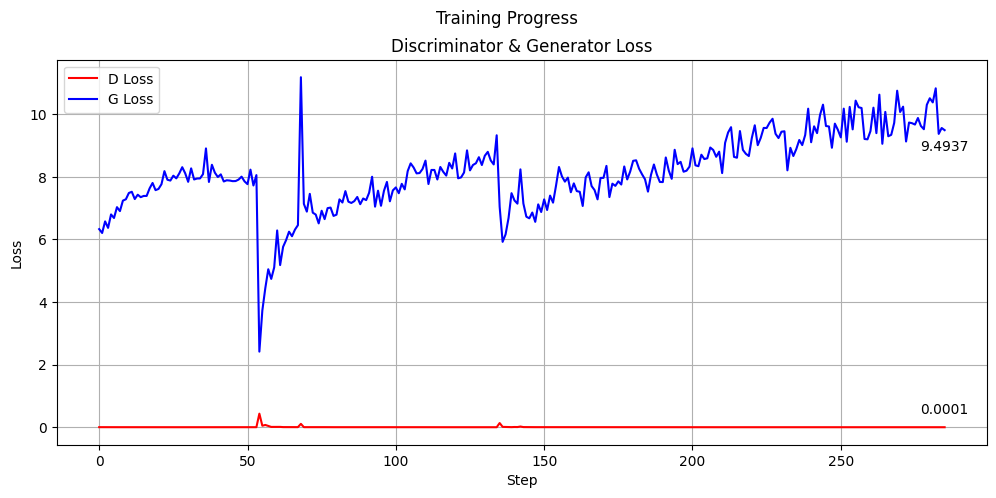

In [ ]:
data = {
    'dLoss': [],
    'gLoss': [],
}

step = 0
for epoch in range(num_epochs):
    for idx, real_images in enumerate(dataloader):
        real_images = real_images.to(device)
        fake_images = generator(fixed_noise)

        dLoss = train_discriminator(discriminator, real_images, fake_images, lossfun, opt_disc, device)
        gLoss = train_generator(generator, discriminator, fake_images, lossfun, opt_gen)

        if idx % 50 == 0:
            save_checkpoint(generator, discriminator)
            log_progress(epoch, num_epochs, idx, dataloader, dLoss, gLoss, writer_fake, writer_real, generator, fixed_noise, step, real_images)
            data['dLoss'].append(dLoss.item())
            data['gLoss'].append(gLoss.item())

            live_plot_dual(data, title='Training Progress')
            step += 1